# Etapa 2 — Análise Exploratória de Dados

Entrada: os CSVs que a Etapa 1 gravou em `../data/raw/`.
Saída: uma tabela horária limpa em `../data/processed/dataset.csv`, mais os
gráficos e as conclusões que sustentam o que você vai afirmar.

As seções abaixo são um roteiro, não uma receita. Responda as perguntas de
cada uma com código e, no fim, em texto. Acrescente seções se quiser.

In [1]:
from pathlib import Path

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Carregar os CSVs

Leia os quatro arquivos de `../data/raw/`.

- Quantas linhas tem cada um? O número faz sentido para o período coletado?
- Os tipos vieram certos, ou datas e números chegaram como texto?
- Há colunas vazias, ou linhas duplicadas?

In [2]:
mares_2025 = pd.read_csv(DIR_RAW / "mares_2025.csv")
mares_prev = pd.read_csv(DIR_RAW / "mares_previsao.csv")
ondas = pd.read_csv(DIR_RAW / "ondas.csv")
vento = pd.read_csv(DIR_RAW / "vento.csv")

In [3]:
print(mares_2025.shape)
print(mares_2025.dtypes)
print(mares_2025.isna().sum())
print(mares_2025.duplicated().sum())
mares_2025.head()

(1410, 6)
data               str
hora               str
altura_m       float64
tipo               str
coeficiente      int64
idade_lua        int64
dtype: object
data           0
hora           0
altura_m       0
tipo           0
coeficiente    0
idade_lua      0
dtype: int64
0


,data,hora,altura_m,tipo,coeficiente,idade_lua
0,2025-01-01,5:50,2.4,alta,81,1
1,2025-01-01,12:00,0.4,baixa,81,1
2,2025-01-01,18:07,2.3,alta,81,1
3,2025-01-02,0:19,0.4,baixa,80,2
4,2025-01-02,6:31,2.4,alta,80,2


In [4]:
print(mares_prev.shape)
print(mares_prev.dtypes)
print(mares_prev.isna().sum())
print(mares_prev.duplicated().sum())
mares_prev.head()

(120, 6)
data               str
hora               str
altura_m       float64
tipo               str
coeficiente      int64
idade_lua        int64
dtype: object
data           0
hora           0
altura_m       0
tipo           0
coeficiente    0
idade_lua      0
dtype: int64
0


,data,hora,altura_m,tipo,coeficiente,idade_lua
0,2026-10-01,0:24,0.4,baixa,64,19
1,2026-10-01,6:45,2.3,alta,64,19
2,2026-10-01,12:54,0.6,baixa,64,19
3,2026-10-01,18:57,2.1,alta,64,19
4,2026-10-02,1:14,0.5,baixa,50,20


In [5]:
print(ondas.shape)
print(ondas.dtypes)
print(ondas.isna().sum())
print(ondas.duplicated().sum())
ondas.head()

(168, 4)
data           str
hora           str
valor      float64
direcao        str
dtype: object
data       0
hora       0
valor      0
direcao    0
dtype: int64
0


,data,hora,valor,direcao
0,2026-10-09,0:00,1.0,ESE
1,2026-10-09,1:00,1.0,ESE
2,2026-10-09,2:00,1.0,ESE
3,2026-10-09,3:00,1.0,ESE
4,2026-10-09,4:00,1.0,ESE


In [6]:
print(vento.shape)
print(vento.dtypes)
print(vento.isna().sum())
print(vento.duplicated().sum())
vento.head()

(168, 4)
data           str
hora           str
valor      float64
direcao        str
dtype: object
data       0
hora       0
valor      0
direcao    0
dtype: int64
0


,data,hora,valor,direcao
0,2026-10-09,0:00,23.0,SE
1,2026-10-09,1:00,22.0,SE
2,2026-10-09,2:00,23.0,SE
3,2026-10-09,3:00,24.0,SE
4,2026-10-09,4:00,24.0,ESE


1. mares_2025 tem 1410 linhas, o que faz sentido, pois é o resultado do numero de marés registradas por dia nos 365 dias do ano, em que a imensa maioria possuía 4 marés por dia.
mares_previsao tem 120 linhas, que é o número de marés que se tem previsão para o mês de outubro inteiro, em que na maioria dos dias são 4 marés por dia, entretanto em alguns dias não tem 4 marés o que diminui um pouco o número de linhas, que seria 124 com os 31 dias de outubro para 120 linhas.
ondas e ventos têm 168 linhas cada, o que é o resultado da métrica de hora em hora que é analisada no período de 7 dias, como são os mesmos dias que são analisados no csv, escolhi por justificá-los juntos.

2. Todos os tipos estavam certos, com exceção de "data" e "hora" que estavam como string.

3. Não há colunas vazias ou linhas duplicadas nos csv´s analisados.

## 2. Limpeza

Deixe cada tabela num estado em que dá para confiar.

- Datas e horas: viram `datetime`? Vale montar uma coluna única de data + hora?
- Decimais: o site usa vírgula. Isso já foi resolvido na Etapa 1 ou sobrou aqui?
- O que fazer com nulos: descartar a linha, preencher, ou manter e documentar?
- Duplicatas: existem? De onde vieram?

In [7]:
for df in (mares_2025, mares_prev, ondas, vento):
    df["datetime"] = pd.to_datetime(df["data"] + " " + df["hora"], format="%Y-%m-%d %H:%M")
    df.drop(columns=["data", "hora"], inplace=True)

ondas = ondas.rename(columns={"valor": "onda_m", "direcao": "onda_dir"})
vento = vento.rename(columns={"valor": "vento_kmh", "direcao": "vento_dir"})

In [8]:
print(ondas.dtypes)
print(ondas["datetime"].is_monotonic_increasing)
print(ondas["onda_dir"].unique(), vento["vento_dir"].unique())
print(ondas["onda_m"].describe())
print(vento["vento_kmh"].describe())

onda_m             float64
onda_dir               str
datetime    datetime64[us]
dtype: object
True
<StringArray>
['ESE', 'E']
Length: 2, dtype: str <StringArray>
['SE', 'ESE', 'E']
Length: 3, dtype: str
count    168.000000
mean       1.163095
std        0.139529
min        0.900000
25%        1.000000
50%        1.200000
75%        1.300000
max        1.400000
Name: onda_m, dtype: float64
count    168.000000
mean      22.702381
std        2.741475
min       17.000000
25%       21.000000
50%       23.000000
75%       24.000000
max       31.000000
Name: vento_kmh, dtype: float64


1. Sim, data e hora viraram datetime. De forma mais simples e direta, sim, vale a pena, principalmente porque na seção 4 as tabelas vão precisar ser juntadas pelo horário e com uma coluna única só é preciso comparar um valor, o que simplifica a junção

2. O problema da vírgula já tinha sido resolvido na etapa 1 ao fazer o scraping, troquei a vírgula por ponto antes de converter para número, então as colunas altura_m, valor e coeficiente já chegaram como números. Não sobrou nada para tratar aqui.

3. Não existiam valores nulos nos meus csv's, então não tive que tomar nenhuma providência com relação a isso.

4. Assim como os valores nulos, não existiam dados duplicados nos meus csv's, então não precisei fazer nada sobre isso.

## 3. Explorar cada tabela separadamente

Antes de juntar, entenda cada fonte.

**Marés** — como a altura se distribui entre marés altas e baixas? O
coeficiente varia ao longo do ano com algum padrão? Ele tem relação com a
fase da lua?

**Ondas** — qual a faixa de altura na janela coletada? Há padrão por hora do
dia, ou a variação é só por dia?

**Vento** — quais horas são mais calmas? A direção predominante muda ao longo
do dia? (Vento da terra para o mar e vento do mar para a terra fazem coisas
opostas com a onda.)

Um gráfico por pergunta. Escreva o que você leu nele.

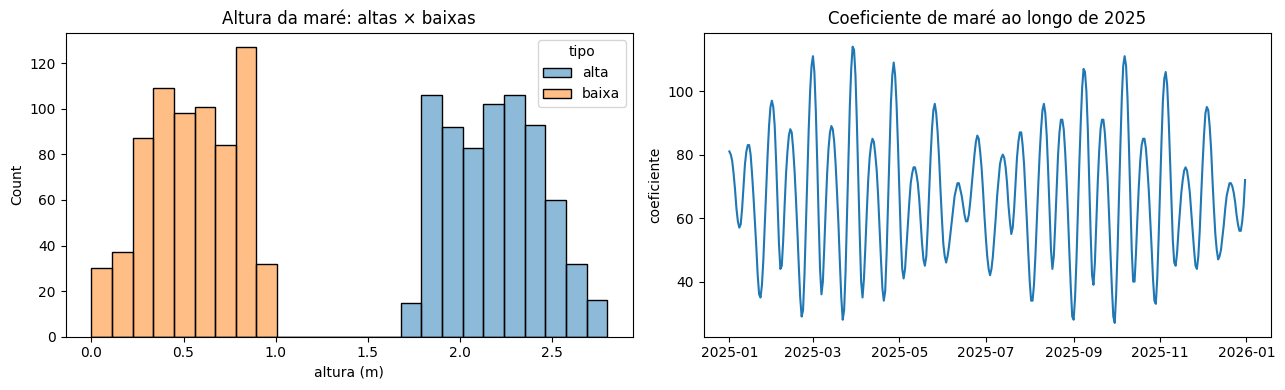

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=mares_2025, x="altura_m", hue="tipo", bins=25, ax=ax[0])
ax[0].set_title("Altura da maré: altas × baixas")
ax[0].set_xlabel("altura (m)")

coef = mares_2025.groupby(mares_2025["datetime"].dt.date)["coeficiente"].first()
ax[1].plot(pd.to_datetime(coef.index), coef.values)
ax[1].set_title("Coeficiente de maré ao longo de 2025")
ax[1].set_ylabel("coeficiente")

plt.tight_layout()
plt.show()

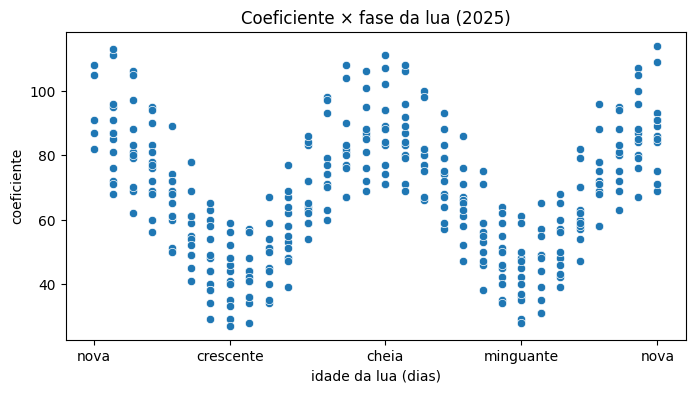

In [10]:
coef_dia = mares_2025.groupby(mares_2025["datetime"].dt.normalize())[["coeficiente", "idade_lua"]].first().reset_index()

fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=coef_dia, x="idade_lua", y="coeficiente", ax=ax)
ax.set_xticks([0, 7, 15, 22, 29])
ax.set_xticklabels(["nova", "crescente", "cheia", "minguante", "nova"])
ax.set_xlabel("idade da lua (dias)")
ax.set_title("Coeficiente × fase da lua (2025)")
plt.show()

1. As marés baixas ficam entre 0,0 e 1,0 m e as altas entre cerca de 1,7 e 2,8 m. Os dois grupos não se sobrepõem, porque há um espaço considerável entre 1,0 (o final da maré baixa) e 1,7 m (o início da maré alta). Então apenas a altura em si já distingue muito o que seria uma maré alta ou maré baixa.

2. O coeficiente oscila entre cerca de 30 e 120 ao longo do ano que foi analisado, mas com amplitudes que alteram-se de forma bastante regular, como se fosse algo cíclico.

3. A fase da lua vem do site: na tábua de marés ela aparece como um ícone, e capturei o número desse ícone na coluna idade_lua (dias desde a lua nova, de 0 a 29). O gráfico mostra uma forte correlação, com o coeficiente sendo muito alto nas fases de lua nova e cheia e muito baixo nas fases crescente e minguante. A correlação é provável olhando para o gráfico porque o quanto mais se aproxima das fases crescente e minguante mais o coeficiente desce e quanto mais se aproxima das fases nova e cheia mais o coeficiente cresce, isso de forma muito regular. 

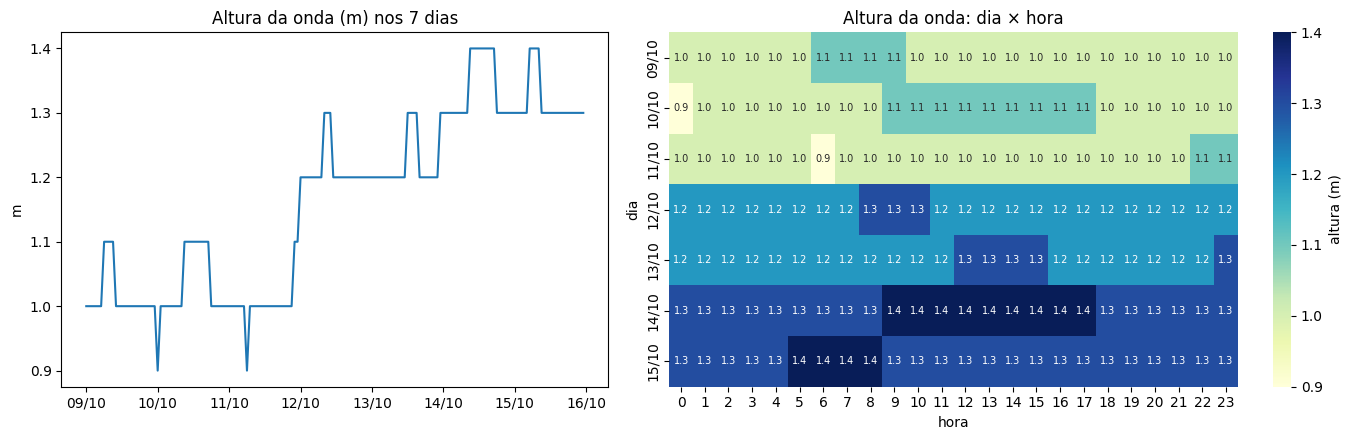

In [11]:
import matplotlib.dates as mdates

ondas["hora"] = ondas["datetime"].dt.hour

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})

ax[0].plot(ondas["datetime"], ondas["onda_m"])
ax[0].xaxis.set_major_locator(mdates.DayLocator())
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax[0].set_title("Altura da onda (m) nos 7 dias")
ax[0].set_ylabel("m")

tabela = ondas.pivot_table(index=ondas["datetime"].dt.strftime("%d/%m"), columns="hora", values="onda_m")
sns.heatmap(tabela, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "altura (m)"},
            ax=ax[1], annot_kws={"size": 7})
ax[1].set_title("Altura da onda: dia × hora")
ax[1].set_xlabel("hora")
ax[1].set_ylabel("dia")

plt.tight_layout()
plt.show()

1. Na janela coletada, a onda vai de 0,9 m a 1,4 m, ficando nos primeiros dias em torno de 1,0m e nos últimos dias em torno de 1,3m.

2. A variação é principalmente por dia, com cada dia tendo uma altura de onda que predomina e a altura da onda tende a aumentar semanalmente, cerca de 1,0 m nos dias 9, 10 e 11; 1,2 m nos dias 12 e 13; e 1,3 m nos dias 14 e 15. Dentro de cada dia, o valor praticamente não muda, e as poucas variações de 0,1 m acontecem em horas diferentes de um dia para outro, sendo de manhã no dia 9 (6h a 9h), à tarde no dia 10 (9h a 17h), à noite no dia 11, etc. Então não há um padrão de repetição com relação às horas do dia com a variação de altura.

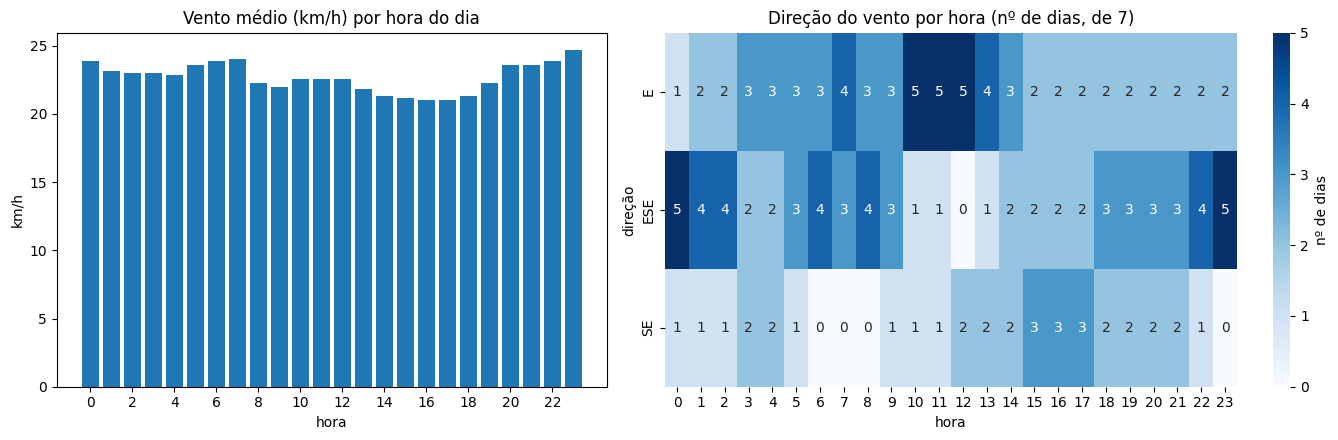

In [12]:
vento["hora"] = vento["datetime"].dt.hour

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})

media = vento.groupby("hora")["vento_kmh"].mean()
ax[0].bar(media.index, media.values)
ax[0].set_title("Vento médio (km/h) por hora do dia")
ax[0].set_xlabel("hora")
ax[0].set_ylabel("km/h")
ax[0].set_xticks(range(0, 24, 2))

tab = pd.crosstab(vento["vento_dir"], vento["hora"])
sns.heatmap(tab, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "nº de dias"}, ax=ax[1])
ax[1].set_title("Direção do vento por hora (nº de dias, de 7)")
ax[1].set_xlabel("hora")
ax[1].set_ylabel("direção")

plt.tight_layout()
plt.show()

1. Os horários com os ventos mais calmos são entre as 14h e as 18h, com uma velocidade do vento um pouco acima do marcador de 20 no gráfico

2. A direção  do vento predominante muda ao longo do dia, os que estão na direção ESE predominam nos horários mais tardes, por volta das 18h até as 2h. No início da madrugada até o começo da tarde o que predomina é o vento na direção E (das 3h até 14h, com certos horários em que ESE predomina, 6h e 8h), os ventos na direção SE não aparecem com tanta frequência como os outros, entretanto o horário em que os ventos SE predominam é das 15h às 17h. Uma conclusão que é possível fazer é a de que esses ventos são no sentido mar-terra, já que eles vêm do leste e o mar em João Pessoa fica no leste.

## 4. Juntar as tabelas

Esta é a parte difícil, e ela tem mais de uma resposta certa.

As granularidades não batem: onda e vento são leituras horárias; maré são ~4
eventos por dia (os instantes de máxima e mínima). Para ter uma linha por hora
com as três informações você precisa decidir:

- Como levar a maré para a grade horária? Interpolar entre eventos? Repetir o
  último valor? Guardar apenas se a maré está subindo ou descendo? O que cada
  escolha assume sobre a curva real da maré — e onde essa suposição erra?
- Qual o tipo de junção? A previsão de onda e a de vento cobrem exatamente as
  mesmas horas? Se não, você mantém as horas incompletas ou corta?
- Que variáveis derivadas de tempo ajudam a responder a pergunta do projeto
  (dia da semana, período do dia, ...)?

Justifique as escolhas em markdown. Elas são a base das duas próximas etapas.

In [13]:
dataset = ondas.drop(columns="hora").merge(vento.drop(columns="hora"), on="datetime", how="inner")

In [14]:
altura = mares_prev.set_index("datetime")["altura_m"]
tipo = mares_prev.set_index("datetime")["tipo"]
grade = dataset["datetime"]
todos = altura.index.union(grade)

dataset["mare_m"] = altura.reindex(todos).interpolate(method="time").reindex(grade).values

ultimo = tipo.reindex(todos).ffill().reindex(grade).values
dataset["mare_fase"] = ["subindo" if t == "baixa" else "descendo" for t in ultimo]

In [15]:
dataset["hora"] = dataset["datetime"].dt.hour
dataset["dia_semana"] = dataset["datetime"].dt.day_name()
dataset["periodo"] = pd.cut(dataset["hora"], [-1, 5, 11, 17, 23],
                            labels=["madrugada", "manha", "tarde", "noite"])

coef = mares_prev.assign(dia=mares_prev["datetime"].dt.date).groupby("dia")["coeficiente"].first()
dataset["coeficiente"] = dataset["datetime"].dt.date.map(coef)

dataset.head()

,onda_m,onda_dir,datetime,vento_kmh,vento_dir,mare_m,mare_fase,hora,dia_semana,periodo,coeficiente
0,1.0,ESE,2026-10-09 00:00:00,23.0,SE,1.500538,subindo,0,Friday,madrugada,95
1,1.0,ESE,2026-10-09 01:00:00,22.0,SE,1.855376,subindo,1,Friday,madrugada,95
2,1.0,ESE,2026-10-09 02:00:00,23.0,SE,2.210215,subindo,2,Friday,madrugada,95
3,1.0,ESE,2026-10-09 03:00:00,24.0,SE,2.434946,descendo,3,Friday,madrugada,95
4,1.0,ESE,2026-10-09 04:00:00,24.0,ESE,2.080108,descendo,4,Friday,madrugada,95


1. Como onda e vento são horárias e a maré só tem os instantes de alta e baixa (cerca de 4 por dia), estimei a altura da maré em cada hora por interpolação linear no tempo entre eventos consecutivos, e guardei também se ela está subindo ou descendo (pelo tipo do último evento). Descartei repetir o último valor, porque a maré não fica parada e o erro seria muito grande. A interpolação linear assume que a maré sobe e desce em ritmo constante, mas a curva real é mais suave, então o erro maior fica entre os eventos.

2. Ondas e vento cobrem exatamente as mesmas 168 horas, então usei inner e não perdi nenhuma linha. A maré entra por interpolação, e não por junção, porque os horários dela não coincidem com os da grade.

3. Hora, dia da semana, período do dia (madrugada, manhã, tarde e noite) e o coeficiente do dia ajudam a responder quando voltar para surfar.

## 5. Visualizações voltadas à pergunta

Agora com a tabela junta: quando as condições coincidem?

- As horas de onda maior são as mesmas de vento mais fraco, ou elas se
  desencontram?
- Existe relação visível entre altura da maré e altura da onda?
- Quais dias e horas da janela se destacam?

Prefira poucos gráficos legíveis a muitos gráficos.

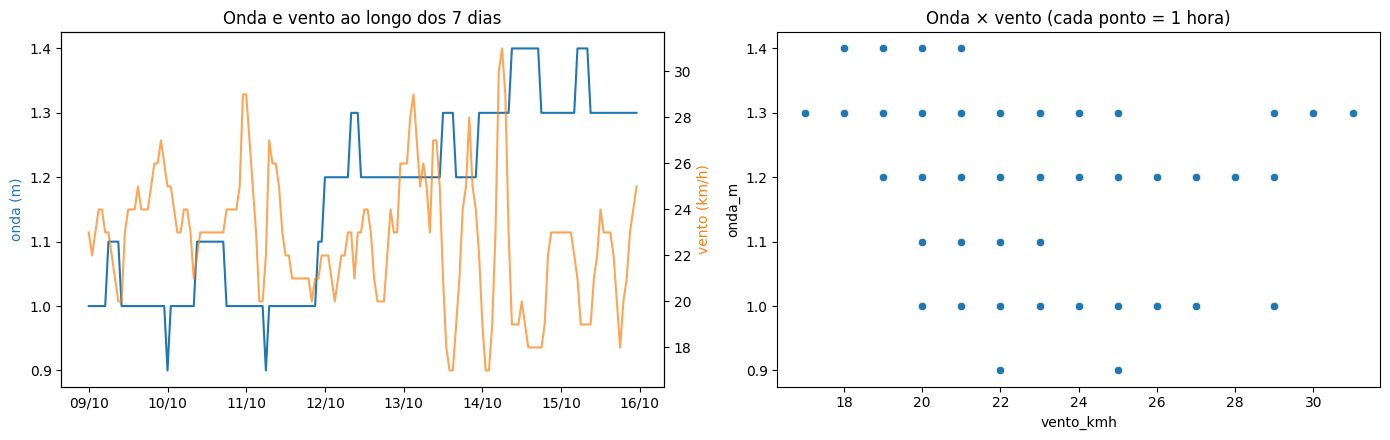

correlação onda × vento: -0.37


In [16]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax2 = ax[0].twinx()
ax[0].plot(dataset["datetime"], dataset["onda_m"], color="tab:blue")
ax2.plot(dataset["datetime"], dataset["vento_kmh"], color="tab:orange", alpha=0.7)
ax[0].set_ylabel("onda (m)", color="tab:blue")
ax2.set_ylabel("vento (km/h)", color="tab:orange")
ax[0].xaxis.set_major_locator(mdates.DayLocator())
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax[0].set_title("Onda e vento ao longo dos 7 dias")

sns.scatterplot(data=dataset, x="vento_kmh", y="onda_m", ax=ax[1])
ax[1].set_title("Onda × vento (cada ponto = 1 hora)")

plt.tight_layout()
plt.show()

print("correlação onda × vento:", round(dataset["onda_m"].corr(dataset["vento_kmh"]), 2))

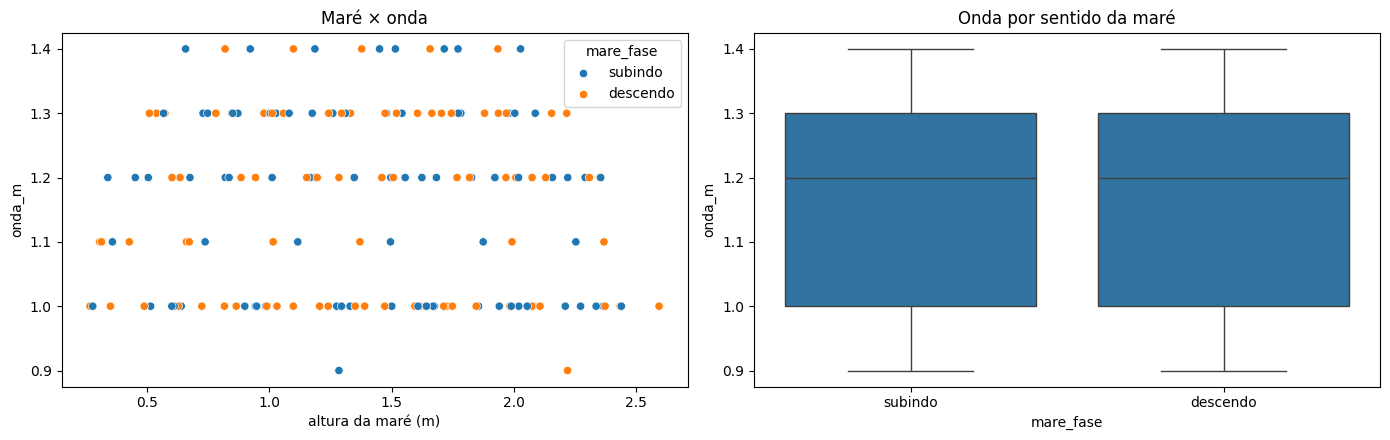

correlação maré × onda: -0.05


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

sns.scatterplot(data=dataset, x="mare_m", y="onda_m", hue="mare_fase", ax=ax[0])
ax[0].set_title("Maré × onda")
ax[0].set_xlabel("altura da maré (m)")

sns.boxplot(data=dataset, x="mare_fase", y="onda_m", ax=ax[1])
ax[1].set_title("Onda por sentido da maré")

plt.tight_layout()
plt.show()

print("correlação maré × onda:", round(dataset["mare_m"].corr(dataset["onda_m"]), 2))

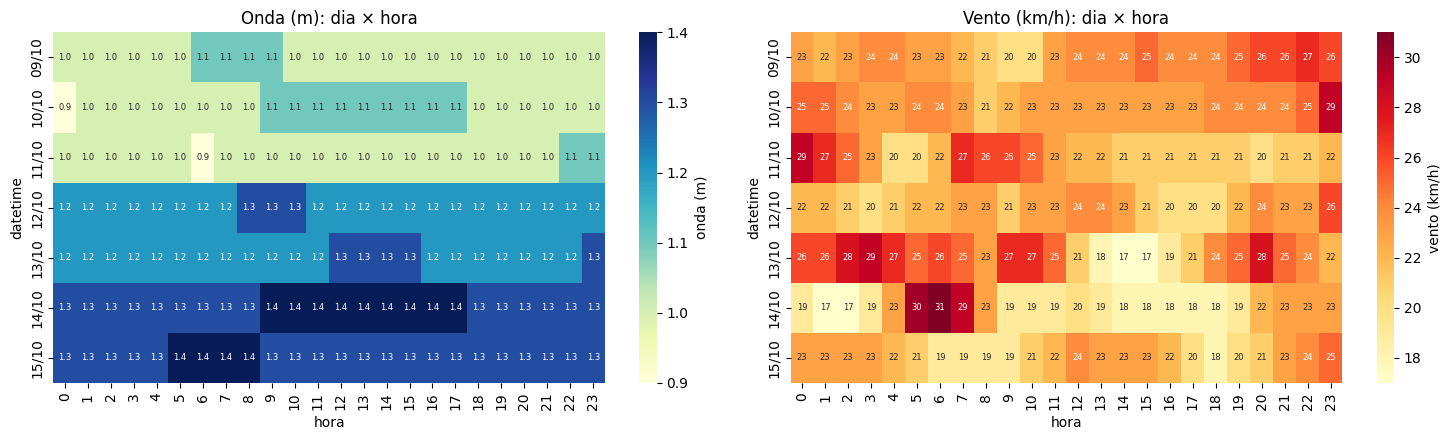

In [18]:
dia = dataset["datetime"].dt.strftime("%d/%m")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

sns.heatmap(dataset.pivot_table(index=dia, columns="hora", values="onda_m"),
            annot=True, fmt=".1f", cmap="YlGnBu", ax=ax[0],
            annot_kws={"size": 6}, cbar_kws={"label": "onda (m)"})
ax[0].set_title("Onda (m): dia × hora")

sns.heatmap(dataset.pivot_table(index=dia, columns="hora", values="vento_kmh"),
            annot=True, fmt=".0f", cmap="YlOrRd", ax=ax[1],
            annot_kws={"size": 6}, cbar_kws={"label": "vento (km/h)"})
ax[1].set_title("Vento (km/h): dia × hora")

plt.tight_layout()
plt.show()

1. Onda e vento há uma tendência fraca de a onda ser maior quando o vento é mais fraco, nos dias 14 e 15, as ondas mais altas coincidem com as menores velocidades de vento. Mas há muitas exceções, e a correlação é de apenas −0,37.

2. Maré e onda não há relação visível entre a altura da maré e a da onda, a nuvem de pontos não tem direção, e a onda é praticamente igual com a maré subindo ou descendo e a correlação é de −0,05.

3. Dias e horas os dias 14 e 15 se destacam, com ondas de 1,3 a 1,4 m e vento mais fraco. Em 14/10, a maior parte do dia mantém onda alta com vento de até 21 km/h.

## 6. Salvar o dataset processado

Grave o resultado em `../data/processed/dataset.csv`. A Etapa 3 lê esse
arquivo — se as colunas mudarem depois, o notebook de ML muda também.

In [19]:
dataset.to_csv(DIR_PROC / "dataset.csv", index=False)

teste = pd.read_csv(DIR_PROC / "dataset.csv", parse_dates=["datetime"])
print(teste.shape)
print(list(teste.columns))
print("nulos:", teste.isna().sum().sum())

(168, 11)
['onda_m', 'onda_dir', 'datetime', 'vento_kmh', 'vento_dir', 'mare_m', 'mare_fase', 'hora', 'dia_semana', 'periodo', 'coeficiente']
nulos: 0


## 7. Conclusões

Em texto, sem código:

1. O que os dados mostram sobre as condições da janela coletada?
2. Que decisão de limpeza ou de junção você tomou que mais influencia o
   resultado, e por quê?
3. O que esses dados **não** permitem afirmar?

1. A altura da onda no período de 09/10 até 15/10 ficou entre 0,9m a 1,4m e o vento 17km/h a 31km/h, que pela conclusão feita é na direção mar-terra. A altura das ondas geralmente cresce de um dia para o outro, com pouquíssimas alterações quando comparadas com outras do mesmo dia e quando cresce nesse ritmo diário acaba sendo de forma relativamente linear, quando o dia passa a onda tende a ser mais alta quando comparada a do dia anterior. Quando foi comparada a correlação entre a velocidade do vento e a altura da onda não foi encontrada uma forte correlação entre ambos, quando a correlação foi calculada ela ficou em -0,37, quando foi comparada a correlação entre a altura da maré e da onda o resultado foi ainda menor, sendo -0,05. Em relação ao coeficiente, ele oscila de forma cíclica e é maior nas luas cheias e novas.

2. A decisão de como levar a maré para a grade horária, como a maré só tem cerca de 4 eventos por dia, estimei a altura em cada hora por interpolação linear e guardei se ela está subindo ou descendo. Essa escolha define as colunas mare_m e mare_fase, que será usada na parte de machine learning, ela assume que a maré sobe e desce em ritmo constante, mas a curva real é mais suave, então o erro maior fica entre os eventos. Já a conversão de data e hora em datetime e a junção por inner não mudam o resultado, porque ondas e vento cobrem exatamente as mesmas 168 horas e não havia nulos nem duplicatas.

3. Não permitem dizer qual é a melhor época do ano para voltar, porque ondas e vento cobrem só 7 dias de uma única semana (só as marés cobrem o ano todo). Também são previsões, e não medições, então podem errar em relação ao que acontecerá de fato. A onda varia pouco (0,9m a 1,4m, em degraus de 0,1m), e uma correlação baixa só indica ausência de correlação visível, e não ausência de qualquer relação. Por fim, a relação entre o coeficiente e a lua foi vista apenas em 2025, com um número de fase por dia.